# CyberMind: pruebas de modelos para la decisión REFUERZO / AVANCE

Este cuaderno reúne, en orden, todo el trabajo de modelado del proyecto:

| # | Sección | Contenido |
|---|---|---|
| 1 | Configuración y datos | Carga del dataset sintético (se regenera si falta) |
| 2 | Exploración | Balance de clases, variables y relación con la etiqueta |
| 3 | Protocolo de evaluación | Partición por estudiante, métricas, intervalo de confianza |
| 4 | Métodos | Regla fija, árbol de decisión, regresión logística, kNN (parámetros e hiperparámetros) |
| 5 | Comparación | Tabla, gráficas y matrices de confusión |
| 6 | Limitaciones | Qué se puede y qué no se puede concluir |
| 7 | Prompt de investigación | Texto para que otro chat busque fuentes creíbles |

**Decisión que se modela:** dado el resultado del diagnóstico de un estudiante en un tema, predecir si necesita **REFUERZO** (clase positiva) o puede pasar a **AVANCE**.

> Los datos son **sintéticos**. Estos resultados validan el procedimiento y el dataset, no la efectividad pedagógica con estudiantes reales.

## 1. Configuración y datos

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.13.18 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


**Datos.** El único archivo necesario es `cybermind_sintetico.csv`, que genera el cuaderno `CyberMind_dataset.ipynb`. Debe estar en la carpeta de trabajo (por ejemplo, subido al panel de archivos de Google Colab).

En el repositorio está en `data/`. No se usa `cybermind_sintetico_oculto.csv`.


In [2]:
# Se busca en la carpeta actual o en ../data (estructura del repositorio)
RUTA_DATOS = next((c / "cybermind_sintetico.csv" for c in (Path.cwd(), Path.cwd().parent / "data")
                   if (c / "cybermind_sintetico.csv").exists()), None)
if RUTA_DATOS is None:
    raise FileNotFoundError("Coloca cybermind_sintetico.csv junto al notebook o en ../data.")
datos = pd.read_csv(RUTA_DATOS)
print("Usando", RUTA_DATOS, "->", datos.shape)
datos.head()

Usando /tmp/claude-0/-home-user/05f6973f-df21-549c-aad8-950eca9b4e01/scratchpad/CyberMind-ML/data/cybermind_sintetico.csv -> (7500, 10)


,id_estudiante,tema,experiencia_previa,aciertos_basico,aciertos_intermedio,aciertos_avanzado,puntaje_tema,puntaje_global,tiempo_promedio_seg,decision
0,E00000,fundamentos_redes,cursos,3,2,0,55.6,73.3,44.9,AVANCE
1,E00000,criptografia,cursos,3,2,2,77.8,73.3,55.1,AVANCE
2,E00000,seguridad_web,cursos,3,3,2,88.9,73.3,31.7,REFUERZO
3,E00000,ingenieria_social,cursos,3,2,1,66.7,73.3,45.4,REFUERZO
4,E00000,gestion_vulnerabilidades,cursos,3,3,1,77.8,73.3,30.5,AVANCE


## 2. Exploración del dataset

Cada fila es un par (estudiante, tema). Las variables de entrada son las que produce el diagnóstico; `decision` es la etiqueta. Ver `diccionario_de_datos.md` para el detalle de cómo se generó cada variable.

In [3]:
print("Balance de la etiqueta:")
print(datos["decision"].value_counts(normalize=True).round(3).to_string())
print("\n% REFUERZO por tema:")
print((datos.groupby("tema")["decision"].apply(lambda s: (s == "REFUERZO").mean()) * 100).round(1).to_string())
print("\n% REFUERZO por experiencia previa:")
print((datos.groupby("experiencia_previa")["decision"].apply(lambda s: (s == "REFUERZO").mean()) * 100).round(1).to_string())
datos.describe().T[["mean", "std", "min", "max"]]

Balance de la etiqueta:
decision
REFUERZO    0.654
AVANCE      0.346

% REFUERZO por tema:
tema
criptografia                77.1
fundamentos_redes           55.1
gestion_vulnerabilidades    70.1
ingenieria_social           48.9
seguridad_web               75.9

% REFUERZO por experiencia previa:
experiencia_previa
cursos     58.6
laboral    42.5
ninguna    77.1


,mean,std,min,max
aciertos_basico,2.372,0.898,0.0,3.0
aciertos_intermedio,1.800,1.043,0.0,3.0
aciertos_avanzado,1.220,0.969,0.0,3.0
puntaje_tema,59.915,24.800,0.0,100.0
puntaje_global,59.909,17.285,13.3,100.0
tiempo_promedio_seg,46.697,20.476,4.0,180.0


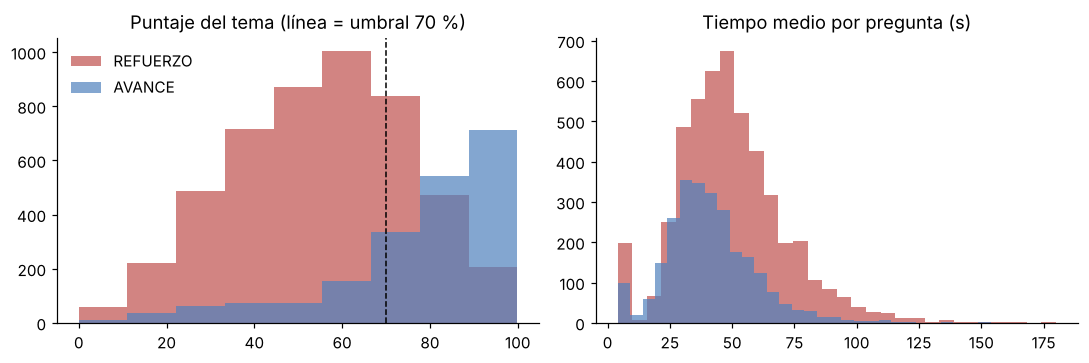

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for clase, color in [("REFUERZO", "#c0504d"), ("AVANCE", "#4f81bd")]:
    sub = datos[datos["decision"] == clase]
    ax[0].hist(sub["puntaje_tema"], bins=np.arange(0, 105, 11.1), alpha=.7, label=clase, color=color)
    ax[1].hist(sub["tiempo_promedio_seg"], bins=30, alpha=.7, label=clase, color=color)
ax[0].axvline(70, ls="--", c="k", lw=1); ax[0].set_title("Puntaje del tema (línea = umbral 70 %)")
ax[1].set_title("Tiempo medio por pregunta (s)"); ax[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Protocolo de evaluación

- **Variables de entrada (8):** `tema`, `experiencia_previa` (categóricas) y `aciertos_basico`, `aciertos_intermedio`, `aciertos_avanzado`, `puntaje_tema`, `puntaje_global`, `tiempo_promedio_seg` (numéricas).
- **Clase positiva:** REFUERZO. Un falso negativo (avanzar sin dominio) es el error más costoso, por eso se reporta también el *recall* de REFUERZO.
- **Partición:** una sola, 75 % entrenamiento / 25 % prueba, con `GroupShuffleSplit(random_state=0)` agrupando por `id_estudiante`: las 5 filas de un estudiante quedan juntas.
- **Prueba:** el conjunto de prueba se usa una sola vez por modelo, al final.
- **Intervalo de confianza:** bootstrap por estudiante (1000 remuestreos, semilla 0) sobre la exactitud. No es una prueba pareada entre modelos.
- **Techo teórico:** acuerdo entre la etiqueta con ruido y la decisión sin ruido (se conoce porque el dataset es sintético).

In [5]:
CATEGORICAS = ["tema", "experiencia_previa"]
NUMERICAS = ["aciertos_basico", "aciertos_intermedio", "aciertos_avanzado", "puntaje_tema", "puntaje_global", "tiempo_promedio_seg"]
X = datos[CATEGORICAS + NUMERICAS]
y = (datos["decision"] == "REFUERZO").astype(int)       # 1 = REFUERZO
grupos = datos["id_estudiante"]

ent, pru = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, groups=grupos))
y_pru = y.iloc[pru].to_numpy()

print(f"Entrenamiento: {len(ent)} filas, {grupos.iloc[ent].nunique()} estudiantes | % REFUERZO = {y.iloc[ent].mean():.1%}")
print(f"Prueba:        {len(pru)} filas, {grupos.iloc[pru].nunique()} estudiantes | % REFUERZO = {y_pru.mean():.1%}")
print(f"Exactitud de predecir siempre REFUERZO: {y_pru.mean():.3f}")


def evaluar(pred):
    """Métricas en prueba + IC 95 % de la exactitud (bootstrap por estudiante)."""
    pred = np.asarray(pred)
    tn, fp, fn, tp = confusion_matrix(y_pru, pred).ravel()
    t = pd.DataFrame({"est": grupos.iloc[pru].to_numpy(), "ok": (pred == y_pru).astype(int)}).groupby("est")["ok"].agg(["sum", "count"])
    idx = np.random.default_rng(0).integers(0, len(t), size=(1000, len(t)))
    boot = t["sum"].to_numpy()[idx].sum(axis=1) / t["count"].to_numpy()[idx].sum(axis=1)
    return {"exactitud": accuracy_score(y_pru, pred), "ic_inf": np.percentile(boot, 2.5), "ic_sup": np.percentile(boot, 97.5),
            "precision": precision_score(y_pru, pred), "recall": recall_score(y_pru, pred), "F1": f1_score(y_pru, pred),
            "VN": tn, "FP": fp, "FN": fn, "VP": tp}

resultados = {}

Entrenamiento: 5625 filas, 1125 estudiantes | % REFUERZO = 64.7%
Prueba:        1875 filas, 375 estudiantes | % REFUERZO = 67.6%
Exactitud de predecir siempre REFUERZO: 0.676


## 4. Métodos

### 4.1 Regla fija (línea base)

**AVANCE si `puntaje_tema` ≥ 70; si no, REFUERZO.** No se entrena. Único parámetro: el umbral de 70 %, fijado por criterio pedagógico (mastery learning), no estimado de los datos. Cualquier modelo debe superarla para justificar su complejidad.

In [6]:
UMBRAL = 70
pred = (X.iloc[pru]["puntaje_tema"] < UMBRAL).astype(int)
resultados["Regla fija"] = evaluar(pred)
pd.Series(resultados["Regla fija"]).round(3)

exactitud       0.813
ic_inf          0.795
ic_sup          0.831
precision       0.858
recall          0.866
F1              0.862
VN            426.000
FP            181.000
FN            170.000
VP           1098.000
dtype: float64

### 4.2 Árbol de decisión (CART)

| Hiperparámetro | Valor | Origen |
|---|---|---|
| `max_depth` | 4 | fijado a mano |
| `min_samples_leaf` | 50 | fijado a mano |
| `random_state` | 0 | reproducibilidad |
| `criterion` | gini | por defecto |
| `splitter`, `min_samples_split`, `class_weight`, `ccp_alpha` | best, 2, None, 0 | por defecto |

**Preprocesamiento:** one-hot en las categóricas; las numéricas pasan sin escalar (el árbol no lo necesita). **No se buscaron hiperparámetros con validación cruzada.**

In [7]:
arbol = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS)],
                               remainder="passthrough", verbose_feature_names_out=False)),
    ("arbol", DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=0)),
])
arbol.fit(X.iloc[ent], y.iloc[ent])
resultados["Árbol de decisión"] = evaluar(arbol.predict(X.iloc[pru]))

nombres_arbol = list(arbol[0].get_feature_names_out())
print("Parámetros del árbol:", arbol[-1].get_params())
print("\nImportancia de variables:")
print(pd.Series(arbol[-1].feature_importances_, index=nombres_arbol).sort_values(ascending=False).loc[lambda s: s > 0].round(3).to_string())
print("\nReglas aprendidas (1 = REFUERZO):")
print(export_text(arbol[-1], feature_names=nombres_arbol))
pd.Series(resultados["Árbol de decisión"]).round(3)

Parámetros del árbol: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 50, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 0, 'splitter': 'best'}

Importancia de variables:
puntaje_tema                  0.892
tiempo_promedio_seg           0.046
puntaje_global                0.028
experiencia_previa_ninguna    0.018
aciertos_avanzado             0.010
tema_ingenieria_social        0.005

Reglas aprendidas (1 = REFUERZO):
|--- puntaje_tema <= 72.25
|   |--- puntaje_tema <= 61.15
|   |   |--- tiempo_promedio_seg <= 18.95
|   |   |   |--- experiencia_previa_ninguna <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- experiencia_previa_ninguna >  0.50
|   |   |   |   |--- class: 1
|   |   |--- tiempo_promedio_seg >  18.95
|   |   |   |--- puntaje_tema <= 50.00
|   |   |   |   |--- class: 1
|   |   |   |--- puntaje_tem

exactitud       0.818
ic_inf          0.798
ic_sup          0.836
precision       0.843
recall          0.897
F1              0.869
VN            395.000
FP            212.000
FN            130.000
VP           1138.000
dtype: float64

### 4.3 Regresión logística

Es un modelo de **clasificación** (a pesar del nombre): estima la probabilidad de REFUERZO y se decide con umbral 0,5. Es el equivalente apropiado de la regresión lineal cuando la variable objetivo es binaria.

| Hiperparámetro | Valor | Origen |
|---|---|---|
| `C` | 1,0 | por defecto (inversa de la fuerza de regularización) |
| Regularización | L2 | por defecto |
| `solver` | lbfgs | por defecto |
| `max_iter` | 1000 | fijado a mano |
| `tol` | 1e-4 | por defecto |
| `class_weight` | None | por defecto |
| Umbral de probabilidad | 0,5 | por defecto |

**Preprocesamiento:** one-hot en las categóricas y `StandardScaler` en las numéricas. **No se buscaron hiperparámetros.**

In [8]:
logit = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
                                ("num", StandardScaler(), NUMERICAS)])),
    ("logit", LogisticRegression(max_iter=1000)),
])
logit.fit(X.iloc[ent], y.iloc[ent])
resultados["Regresión logística"] = evaluar(logit.predict(X.iloc[pru]))

coef = pd.Series(logit[-1].coef_[0], index=logit[0].get_feature_names_out()).sort_values(key=abs, ascending=False)
print(f"Intercepto: {logit[-1].intercept_[0]:.3f}")
print("Coeficientes (variables estandarizadas; positivo = más riesgo de REFUERZO):")
print(coef.round(3).to_string())
pd.Series(resultados["Regresión logística"]).round(3)

Intercepto: 0.554
Coeficientes (variables estandarizadas; positivo = más riesgo de REFUERZO):
cat__experiencia_previa_ninguna       0.553
num__aciertos_intermedio             -0.545
cat__tema_seguridad_web               0.520
cat__tema_criptografia                0.495
cat__tema_ingenieria_social          -0.479
num__tiempo_promedio_seg              0.460
num__puntaje_tema                    -0.428
num__aciertos_avanzado               -0.388
num__puntaje_global                  -0.342
cat__tema_gestion_vulnerabilidades    0.256
cat__tema_fundamentos_redes          -0.250
cat__experiencia_previa_laboral      -0.107
cat__experiencia_previa_cursos        0.096
num__aciertos_basico                 -0.020


exactitud       0.825
ic_inf          0.806
ic_sup          0.842
precision       0.850
recall          0.899
F1              0.874
VN            406.000
FP            201.000
FN            128.000
VP           1140.000
dtype: float64

### 4.4 kNN (k vecinos más cercanos)

Es el único método con **búsqueda de hiperparámetros**: validación cruzada agrupada de 5 particiones (`GroupKFold`) usando solo el conjunto de entrenamiento, con la exactitud como métrica. 40 combinaciones.

| Hiperparámetro | Valores probados |
|---|---|
| `n_neighbors` | 1, 3, 5, 9, 15, 25, 35, 51, 75, 101 |
| `weights` | uniform, distance |
| `p` | 1 (Manhattan), 2 (euclídea) |

**Preprocesamiento:** one-hot en las categóricas y `StandardScaler` en las numéricas (escalar es obligatorio en kNN: sin esto dominarían las variables de mayor rango).

Mejores hiperparámetros: {'knn__n_neighbors': 51, 'knn__p': 1, 'knn__weights': 'uniform'}
Exactitud en validación cruzada (entrenamiento): 0.817


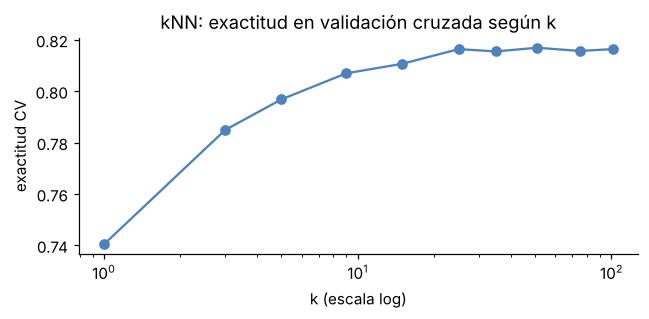

exactitud       0.830
ic_inf          0.813
ic_sup          0.848
precision       0.860
recall          0.894
F1              0.877
VN            423.000
FP            184.000
FN            134.000
VP           1134.000
dtype: float64

In [9]:
rejilla = {"knn__n_neighbors": [1, 3, 5, 9, 15, 25, 35, 51, 75, 101], "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]}
knn = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
                                ("num", StandardScaler(), NUMERICAS)])),
    ("knn", KNeighborsClassifier()),
])
gs = GridSearchCV(knn, rejilla, scoring="accuracy", cv=GroupKFold(n_splits=5), n_jobs=-1)
gs.fit(X.iloc[ent], y.iloc[ent], groups=grupos.iloc[ent])
resultados["kNN"] = evaluar(gs.predict(X.iloc[pru]))

print("Mejores hiperparámetros:", gs.best_params_)
print(f"Exactitud en validación cruzada (entrenamiento): {gs.best_score_:.3f}")
cv = pd.DataFrame(gs.cv_results_)
por_k = cv.groupby("param_knn__n_neighbors")["mean_test_score"].max()
ax = por_k.plot(marker="o", figsize=(6, 3), color="#4f81bd")
ax.set_xscale("log"); ax.set_xlabel("k (escala log)"); ax.set_ylabel("exactitud CV"); ax.set_title("kNN: exactitud en validación cruzada según k")
plt.tight_layout(); plt.show()
pd.Series(resultados["kNN"]).round(3)

## 5. Comparación de los cuatro métodos

In [10]:
tabla = pd.DataFrame(resultados).T
tabla["IC 95 % exactitud"] = tabla.apply(lambda r: f"[{r.ic_inf:.3f}, {r.ic_sup:.3f}]", axis=1)
vista = tabla[["exactitud", "IC 95 % exactitud", "precision", "recall", "F1", "VN", "FP", "FN", "VP"]].rename(
    columns={"precision": "precisión REFUERZO", "recall": "recall REFUERZO", "F1": "F1 REFUERZO",
             "VN": "AVANCE ok", "FP": "refuerzo innecesario", "FN": "avance sin dominio", "VP": "REFUERZO ok"})
print(f"Siempre REFUERZO: {y_pru.mean():.3f}")
vista

Siempre REFUERZO: 0.676


,exactitud,IC 95 % exactitud,precisión REFUERZO,recall REFUERZO,F1 REFUERZO,AVANCE ok,refuerzo innecesario,avance sin dominio,REFUERZO ok
Regla fija,0.813,"[0.795, 0.831]",0.858,0.866,0.862,426.0,181.0,170.0,1098.0
Árbol de decisión,0.818,"[0.798, 0.836]",0.843,0.897,0.869,395.0,212.0,130.0,1138.0
Regresión logística,0.825,"[0.806, 0.842]",0.850,0.899,0.874,406.0,201.0,128.0,1140.0
kNN,0.830,"[0.813, 0.848]",0.860,0.894,0.877,423.0,184.0,134.0,1134.0


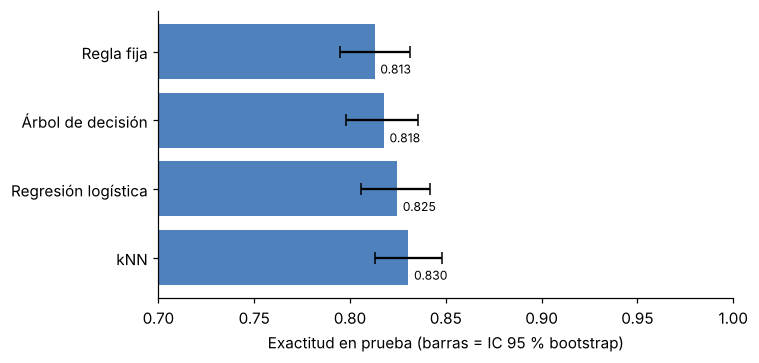

In [11]:
orden = list(resultados)
ex = np.array([resultados[m]["exactitud"] for m in orden])
err = np.array([[resultados[m]["exactitud"] - resultados[m]["ic_inf"], resultados[m]["ic_sup"] - resultados[m]["exactitud"]] for m in orden]).T
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(orden, ex, xerr=err, color="#4f81bd", capsize=4)
ax.set_xlim(0.70, 1.0); ax.invert_yaxis(); ax.set_xlabel("Exactitud en prueba (barras = IC 95 % bootstrap)")
for i, v in enumerate(ex): ax.text(v + .003, i + .32, f"{v:.3f}", fontsize=8)
plt.tight_layout(); plt.show()

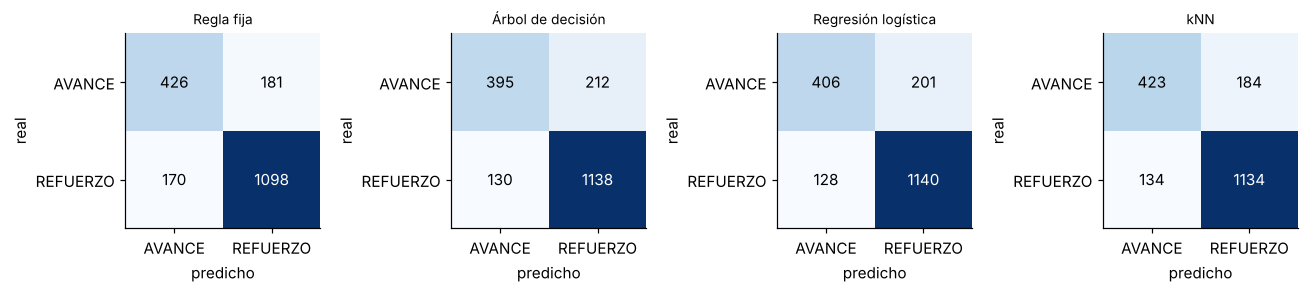

In [12]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3))
for a, m in zip(axs, orden):
    r = resultados[m]
    mat = np.array([[r["VN"], r["FP"]], [r["FN"], r["VP"]]])
    a.imshow(mat, cmap="Blues")
    for (i, j), v in np.ndenumerate(mat): a.text(j, i, int(v), ha="center", va="center", color="white" if v > mat.max() / 2 else "black")
    a.set_xticks([0, 1], ["AVANCE", "REFUERZO"]); a.set_yticks([0, 1], ["AVANCE", "REFUERZO"])
    a.set_title(m, fontsize=9); a.set_xlabel("predicho"); a.set_ylabel("real")
plt.tight_layout(); plt.show()

## 6. Limitaciones y lectura de los resultados

1. **Diferencias pequeñas.** Los cuatro modelos están entre 0,813 y 0,830 de exactitud y sus intervalos de confianza se solapan casi por completo. Con esta partición no se puede afirmar que uno sea mejor. (El bootstrap por estudiante no es una comparación pareada; una prueba pareada, como McNemar o el bootstrap de la diferencia, sería más sensible.)
2. **Comparación no del todo pareja.** Solo kNN tuvo búsqueda de hiperparámetros. El árbol y la logística usaron valores fijados a mano o por defecto.
3. **Una sola partición.** No hay validación cruzada del procedimiento completo ni repetición con varias semillas.
4. **Datos sintéticos.** Un modelo entrenado aquí aprende las relaciones que el generador supone. Los resultados validan el procedimiento y la arquitectura, no la efectividad pedagógica.
5. **Techo de 0,947.** La distancia entre ~0,82 y ~0,95 se debe sobre todo a que 9 preguntas por tema miden el dominio con ruido, no al algoritmo.
6. **Costo asimétrico no aplicado.** Se usó umbral 0,5 sin ponderar clases, aunque avanzar sin dominio (FN) cuesta más que un refuerzo innecesario (FP). Ajustar umbral o `class_weight` es trabajo pendiente.

**Siguiente paso sugerido:** misma validación cruzada agrupada y búsqueda de hiperparámetros para los cuatro métodos, varias semillas de partición y comparación pareada.

## 7. Prompt para investigar fuentes en otro chat

Copiar el contenido del bloque siguiente en un chat nuevo. También está en `Prompt_investigacion_fuentes.md`.

````text
Actúa como investigador académico. Necesito una revisión de fuentes con credibilidad verificable sobre cómo otras industrias, entidades e investigadores han entrenado modelos de IA para resolver problemas parecidos al mío. Responde en español.

## Mi problema (contexto)

Proyecto universitario "CyberMind": una app de formación en ciberseguridad con un servicio de IA independiente. Después de una evaluación diagnóstica por tema (9 preguntas: 3 básicas, 3 intermedias, 3 avanzadas), el servicio debe decidir, para cada estudiante y tema, REFUERZO (necesita repasar antes de avanzar) o AVANCE (puede pasar a la unidad siguiente). Es una clasificación binaria supervisada basada en el principio de aprendizaje de dominio (mastery learning, umbral de ~70 % de probabilidad de aprobar la unidad siguiente).

Características de mi situación, que quiero que las fuentes reflejen:
- **Pocos datos o ninguno real al inicio:** hoy uso un dataset sintético (1.500 estudiantes × 5 temas, generado con Teoría de Respuesta al Ítem 3PL con 5 % de ruido en la etiqueta). Los datos reales llegarían después de un piloto.
- **Variables de entrada:** aciertos por nivel, puntaje del tema, puntaje global, tiempo medio de respuesta, experiencia previa declarada y tema (tabular, 8 variables).
- **Modelos que he probado:** regla fija por umbral, árbol de decisión (CART), regresión logística y kNN. Todos quedan entre 81 % y 83 % de exactitud sobre datos sintéticos (techo teórico ≈ 95 %).
- **Exigencias:** el modelo debe ser interpretable (explicar la decisión al estudiante y al docente), y un error de "avanzar sin dominio" cuesta más que un "refuerzo innecesario".
- Fuera de alcance: estilos de aprendizaje (VARK), knowledge tracing profundo y aprendizaje por refuerzo. No me interesan fuentes centradas en eso.

## Qué debes investigar

Busca técnicas, enfoques y resultados que otras personas o entidades hayan usado en problemas análogos. Cubre estas áreas, y añade otras si ves que son más pertinentes:

1. **Educación y tutores inteligentes:** decisiones de nivelación o colocación (placement), predicción de dominio o de estudiantes en riesgo, sistemas de alerta temprana (early warning), tutores adaptativos (por ejemplo ALEKS y Knowledge Space Theory, Carnegie Learning, Khan Academy, Duolingo), pruebas adaptativas computarizadas (CAT) e IRT.
2. **Datos sintéticos y simuladores de estudiantes:** cómo se genera y valida este tipo de datos (simulación con IRT, simuladores de estudiantes, CTGAN o SDV para datos tabulares), qué riesgos tiene entrenar con datos sintéticos y cómo se evalúa que sirvan para el mundo real (TSTR: train on synthetic, test on real).
3. **Otras industrias con decisión binaria tabular, pocos datos y exigencia de interpretabilidad:** triaje y diagnóstico clínico, scorecards de crédito, mantenimiento predictivo, selección de personal con evaluaciones, detección de fraude. Interesa qué modelo usan y por qué (por ejemplo árboles, scorecards, regresión logística, modelos aditivos como EBM), no la industria en sí.
4. **Entrenamiento y evaluación con pocos datos:** validación cruzada agrupada por individuo, ajuste de hiperparámetros, calibración de probabilidades, elección de umbral con costos asimétricos, intervalos de confianza para métricas y comparación pareada de modelos.
5. **Ciberseguridad:** plataformas de formación adaptativa (cyber ranges, CTF educativos, awareness training) que decidan nivel o refuerzo.

## Criterios de credibilidad (obligatorios)

- Prioriza: artículos con revisión por pares (revistas y congresos indexados en Scopus, Web of Science, IEEE Xplore, ACM DL, Springer, Elsevier), reportes de organismos reconocidos (NIST, OECD, UNESCO, ISO) y documentación técnica oficial de la librería o empresa (por ejemplo scikit-learn, el sitio de la Open University).
- Se acepta literatura gris (preprints en arXiv, blogs técnicos de empresas) solo si la marcas como tal y no es tu única fuente de una afirmación.
- Excluye blogs personales, tutoriales sin referencias, contenido promocional y resúmenes generados por IA.
- Prefiere trabajos de 2018 a hoy, salvo clásicos fundacionales (indica que lo son).

## Reglas para evitar errores

- **No inventes referencias.** Cada fuente debe tener autores, año, título, medio y enlace o DOI que hayas encontrado y abierto realmente. Si no puedes verificar una fuente, no la incluyas.
- Separa lo que **dice la fuente** de lo que **tú interpretas**. Si una cifra no aparece en el texto que leíste, no la cites.
- Si una afirmación solo tiene una fuente débil, márcala como "evidencia limitada".
- Si no encuentras nada creíble para un área, dilo explícitamente.

## Formato de la respuesta

1. **Resumen ejecutivo** (máx. 10 líneas): qué técnicas aparecen más y cuál sería la mejor para mi caso.
2. **Tabla de fuentes** con estas columnas: n.º, cita completa (formato IEEE), enlace o DOI, tipo de fuente (artículo, congreso, reporte, documentación, preprint), área (de las 5 anteriores), problema que resuelven, datos que usaron (tamaño y si eran reales o sintéticos), técnica y modelo, hiperparámetros o configuración si los reportan, métricas y resultados, limitaciones declaradas y relevancia para mi caso (alta, media o baja, con una frase de justificación).
3. **Técnicas que debería considerar** (máx. 8): para cada una, qué es, quién la usó y para qué, qué ventaja tiene sobre lo que ya probé y qué datos necesitaría.
4. **Lo que NO funcionó o no se recomienda** según las fuentes (por ejemplo riesgos de datos sintéticos o de modelos opacos).
5. **Preguntas abiertas y vacíos**: qué no encontraste y qué habría que validar con datos reales.
6. **Referencias** numeradas en formato IEEE, en el orden en que las citas en el texto.

Antes de responder, dime brevemente cuántas fuentes verificaste y cuántas descartaste por no poder verificarlas.
````

## 8. Archivos del proyecto

| Archivo | Contenido |
|---|---|
| `notebooks/01_generacion_dataset.ipynb` | Cuaderno aparte que genera y verifica el dataset (semilla 42) |
| `data/cybermind_sintetico.csv` | Dataset de entrenamiento y prueba |
| `data/diccionario_de_datos.md` | Descripción de cada variable y de la etiqueta |
| `pruebas/fase1_comparacion_modelos/01_regla_fija.py` … `05_gbdt.py` | Un script independiente por método |
| `pruebas/fase1_comparacion_modelos/resultados/*.json` | Resultados de cada script |
| `docs/Documentacion_pruebas_modelos.docx` | Documento con toda la documentación de las pruebas |